# 📘 6.5 Multidimensional Integration

### Accumulating distributed quantities over areas and volumes

Many engineering quantities are distributed across more than one coordinate:

* pressure acts across a surface;
* density varies through a component volume;
* heat generation varies through a body;
* rainfall or pollutant concentration varies over a region; and
* probability density varies across several uncertain inputs.

A one-dimensional integral adds contributions along a line. A double integral
adds contributions across an area, and a triple integral adds contributions
through a volume.

This notebook uses a pressure-loaded plate to connect the mathematics to
resultant force and centre of pressure. It then develops callable-function,
Gaussian, sampled-grid and three-dimensional workflows.


## Before you begin: dimensions describe the domain, not difficulty

A double-integral symbol can look intimidating, but the physical action remains
familiar: divide a region into small pieces, calculate the contribution from each
piece and add them.

We use $I$ for an ideal multidimensional integral and $Q$ for a numerical
approximation, so $Q\approx I$. Neither symbol replaces the other. Additional
symbols will be defined before use.

Focus on four questions:

1. What quantity is distributed?
2. What region or volume is being covered?
3. What are the units of one small contribution?
4. Do the function arguments, bounds and array axes represent the same geometry?

Multidimensional integration is useful when accumulation over an area, volume or
parameter space answers the engineering question. It is not automatically useful
for every table or image. If the required result is a maximum stress, crack
location, dominant frequency or local defect, an integral alone may hide the
behaviour that matters.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* interpret double and triple integrals as physical accumulation;
* define an integration region and write consistent iterated bounds;
* track units through area and volume integration;
* calculate resultant force and centre of pressure from a pressure field;
* use `scipy.integrate.dblquad` with the correct argument order;
* construct tensor-product Gauss–Legendre quadrature on a rectangle;
* integrate over a region with coordinate-dependent bounds;
* integrate gridded sampled data along documented array axes;
* use `scipy.integrate.nquad` for a simple three-dimensional problem; and
* explain why tensor-product evaluation cost grows rapidly with dimension.

### 🔗 Unit Learning Outcome Alignment

This notebook supports:

* **LO1:** Assess the suitability and limitations of numerical analysis tools.
* **LO2:** Develop defensible solutions to open-ended engineering problems.
* **LO3:** Evaluate numerical performance, error, stability and accuracy.

### 📚 Sources used in this notebook

* SciPy — [`integrate.dblquad`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.dblquad.html)
* SciPy — [`integrate.nquad`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.nquad.html)
* SciPy — [General multiple integration](https://docs.scipy.org/doc/scipy/tutorial/integrate.html#general-multiple-integration-dblquad-tplquad-nquad)
* NumPy — [`meshgrid`](https://numpy.org/doc/stable/reference/generated/numpy.meshgrid.html)


## 📂 6.5.0 How to use this notebook

This is a **pre-work content notebook**. Run every cell from top to bottom; no
cell requires editing or typed input. All datasets are generated locally and
deterministically.

This notebook completes the Week 6 content sequence. The Week 6 student and tutor
workbooks will be developed after the five topic notebooks are approved.


### 📖 Core language for 6.5

* The **domain** $\Omega$ is the area or volume over which integration occurs.
* The **integrand** is the distributed quantity being accumulated.
* An **iterated integral** performs one one-dimensional integral inside another.
* An **inner bound** may depend on the outer coordinate for a non-rectangular
  domain.
* A **resultant** replaces a distributed load with one equivalent total load.
* A **first moment** weights a distributed quantity by a coordinate.
* A **tensor-product rule** combines one-dimensional nodes and weights across
  coordinate directions.
* A **sampled grid** contains values at combinations of coordinate vectors.
* An array **axis** identifies which dimension changes with a coordinate.
* **Cubature** is a general term for multidimensional numerical integration.


In [ ]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from numpy.polynomial.legendre import leggauss
from scipy.integrate import dblquad, nquad, trapezoid

pd.set_option("display.precision", 9)
plt.rcParams["figure.figsize"] = (8.5, 5.0)


## 📂 6.5.1 From small area contributions to a double integral

Let $q(x,y)$ be a quantity distributed across a two-dimensional region $\Omega$.
A small rectangular area is

$$\Delta A\approx \Delta x\,\Delta y.$$

Its contribution is approximately

$$q(x,y)\Delta A.$$

Adding all contributions and taking the limiting case gives

$$
I=\iint_{\Omega}q(x,y)\,\mathrm{d}A.
$$

Here:

* $I$ is the ideal accumulated quantity;
* $\Omega$ is the integration region;
* $x$ and $y$ are coordinates;
* $q(x,y)$ is the integrand; and
* $\mathrm{d}A$ is a differential area element.

If $q$ has units per square metre, multiplying by $\mathrm{d}A$ removes the
per-area part of the units.


### Physical-unit examples

| Distributed quantity | Integral | Resulting units |
|---|---|---|
| pressure $p$ [N/m$^2$] | $\iint p\,\mathrm{d}A$ | resultant force [N] |
| heat flux $q''$ [W/m$^2$] | $\iint q''\,\mathrm{d}A$ | heat-transfer rate [W] |
| surface mass density $\sigma$ [kg/m$^2$] | $\iint \sigma\,\mathrm{d}A$ | mass [kg] |
| volume density $\rho$ [kg/m$^3$] | $\iiint \rho\,\mathrm{d}V$ | mass [kg] |

Unit checking is especially valuable in multidimensional integration because a
missing coordinate integration leaves an extra metre in the denominator.


## 📂 6.5.2 Rectangular domains and iterated integration

For a rectangle

$$a\leq x\leq b,\qquad c\leq y\leq d,$$

the double integral can be written as an iterated integral:

$$
I=\int_a^b\left[\int_c^d q(x,y)\,\mathrm{d}y\right]\mathrm{d}x.
$$

The inner integral first accumulates along $y$ while $x$ is held fixed. The outer
integral then accumulates those strip results along $x$.

For a well-behaved integrand on a rectangular domain, the order can often be
reversed. The code implementation must still match the chosen order and bounds.


In [ ]:
# Verification case: integrate q(x, y) = 1 over a 1.2 m by 0.8 m rectangle.
plate_length_m = 1.2
plate_height_m = 0.8

area_value, area_error_estimate = dblquad(
    lambda y, x: 1.0,
    0.0,
    plate_length_m,
    0.0,
    plate_height_m,
)

print(f"Integrated area: {area_value:.8f} m^2")
print(f"Geometric area:  {plate_length_m * plate_height_m:.8f} m^2")
print(f"dblquad error estimate: {area_error_estimate:.2e} m^2")


Integrated area: 0.96000000 m^2
Geometric area:  0.96000000 m^2
dblquad error estimate: 1.07e-14 m^2


`dblquad` expects the callable arguments in the order `function(y, x)`, even
though the outer coordinate $x$ is listed first in the integration bounds. This
reflects the inner-$y$, outer-$x$ integration order.

The returned error estimate describes the adaptive numerical calculation. It is
not measurement uncertainty or modelling uncertainty.


## 📂 6.5.3 Engineering example: pressure on a rectangular plate

A plate occupies

$$0\leq x\leq L,\qquad 0\leq y\leq H,$$

where $L=1.2$ m and $H=0.8$ m. The pressure model is

$$
p(x,y)=p_0\left[1+\alpha\frac{x}{L}
+\beta\frac{y}{H}+\gamma\frac{xy}{LH}\right],
$$

with $p_0=80$ kPa, $\alpha=0.45$, $\beta=-0.25$ and $\gamma=0.15$.

The symbols mean:

* $p(x,y)$: pressure at coordinate $(x,y)$;
* $p_0$: reference pressure;
* $L,H$: plate dimensions; and
* $\alpha,\beta,\gamma$: dimensionless pressure-gradient coefficients.

This is a deterministic teaching model, not pressure data from a certified design
case.


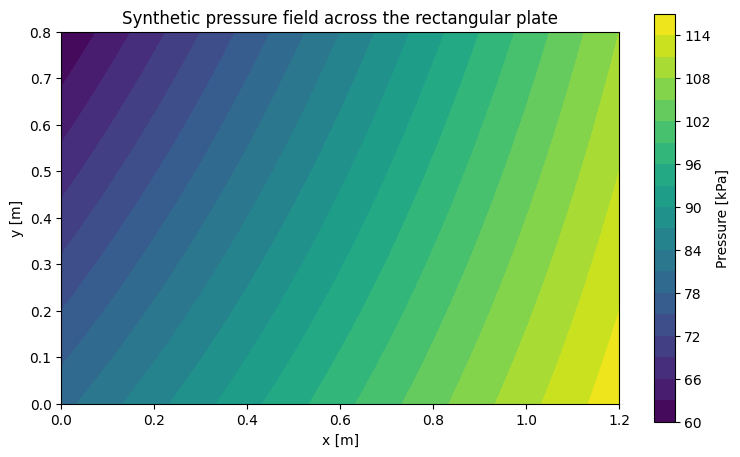

In [ ]:
reference_pressure_Pa = 80_000.0
alpha_pressure = 0.45
beta_pressure = -0.25
gamma_pressure = 0.15


def plate_pressure_Pa(x_m, y_m):
    x_m = np.asarray(x_m, dtype=float)
    y_m = np.asarray(y_m, dtype=float)
    return reference_pressure_Pa * (
        1.0
        + alpha_pressure * x_m / plate_length_m
        + beta_pressure * y_m / plate_height_m
        + gamma_pressure * x_m * y_m / (plate_length_m * plate_height_m)
    )


x_plot = np.linspace(0.0, plate_length_m, 181)
y_plot = np.linspace(0.0, plate_height_m, 141)
X_plot, Y_plot = np.meshgrid(x_plot, y_plot, indexing="xy")
pressure_plot_kPa = plate_pressure_Pa(X_plot, Y_plot) / 1000.0

fig, ax = plt.subplots(figsize=(9.0, 5.3))
contour = ax.contourf(X_plot, Y_plot, pressure_plot_kPa, levels=18, cmap="viridis")
fig.colorbar(contour, ax=ax, label="Pressure [kPa]")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title("Synthetic pressure field across the rectangular plate")
ax.set_aspect("equal")
plt.show()


## 📂 6.5.4 Resultant force and centre of pressure

The distributed pressure is replaced by an equivalent resultant force

$$
F_R=\int_0^L\int_0^H p(x,y)\,\mathrm{d}y\,\mathrm{d}x.
$$

Here $F_R$ is the resultant normal force in newtons. Two first moments locate its
line of action:

$$
M_y=\int_0^L\int_0^H x\,p(x,y)\,\mathrm{d}y\,\mathrm{d}x,
$$

$$
M_x=\int_0^L\int_0^H y\,p(x,y)\,\mathrm{d}y\,\mathrm{d}x.
$$

$M_y$ is the pressure moment about the $y$-axis and $M_x$ is the pressure moment
about the $x$-axis. Their units are N m. The centre-of-pressure coordinates are

$$
x_{\mathrm{cp}}=\frac{M_y}{F_R},
\qquad
y_{\mathrm{cp}}=\frac{M_x}{F_R}.
$$

The subscript `cp` means centre of pressure. These coordinates do not replace the
integration coordinates $x$ and $y$.


In [ ]:
def pressure_yx(y_m, x_m):
    # dblquad requires the inner variable y first and outer variable x second.
    return plate_pressure_Pa(x_m, y_m)


resultant_force_N, force_error_estimate = dblquad(
    pressure_yx,
    0.0,
    plate_length_m,
    0.0,
    plate_height_m,
)
moment_about_y_Nm, _ = dblquad(
    lambda y_m, x_m: x_m * plate_pressure_Pa(x_m, y_m),
    0.0,
    plate_length_m,
    0.0,
    plate_height_m,
)
moment_about_x_Nm, _ = dblquad(
    lambda y_m, x_m: y_m * plate_pressure_Pa(x_m, y_m),
    0.0,
    plate_length_m,
    0.0,
    plate_height_m,
)

x_cp_m = moment_about_y_Nm / resultant_force_N
y_cp_m = moment_about_x_Nm / resultant_force_N

pressure_result = pd.DataFrame(
    {
        "Quantity": ["Resultant force", "Moment about y", "Moment about x", "x_cp", "y_cp"],
        "Value": [resultant_force_N, moment_about_y_Nm, moment_about_x_Nm, x_cp_m, y_cp_m],
        "Units": ["N", "N m", "N m", "m", "m"],
    }
)
display(pressure_result)
print(f"dblquad force error estimate: {force_error_estimate:.3e} N")


,Quantity,Value,Units
0,Resultant force,87360.000000000,N
1,Moment about y,56448.000000000,N m
2,Moment about x,34048.000000000,N m
3,x_cp,0.646153846,m
4,y_cp,0.389743590,m


dblquad force error estimate: 9.939e-10 N


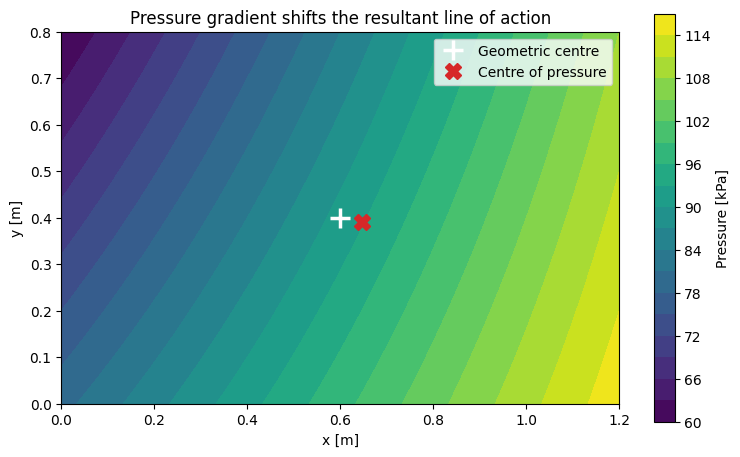

In [ ]:
fig, ax = plt.subplots(figsize=(9.0, 5.3))
contour = ax.contourf(X_plot, Y_plot, pressure_plot_kPa, levels=18, cmap="viridis")
fig.colorbar(contour, ax=ax, label="Pressure [kPa]")
ax.plot(
    plate_length_m / 2,
    plate_height_m / 2,
    "+",
    markersize=14,
    markeredgewidth=2.5,
    color="white",
    label="Geometric centre",
)
ax.plot(x_cp_m, y_cp_m, "X", markersize=11, color="tab:red", label="Centre of pressure")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title("Pressure gradient shifts the resultant line of action")
ax.set_aspect("equal")
ax.legend()
plt.show()


The centre of pressure moves toward higher pressure. A useful validation case is
$\alpha=\beta=\gamma=0$: uniform pressure must place the resultant at the
geometric centre $(L/2,H/2)$.


## 📂 6.5.5 Tensor-product Gauss–Legendre quadrature

For a rectangle, one-dimensional Gaussian rules can be combined. Let:

* $x_i$ and $W_i^{(x)}$ be mapped nodes and weights in the $x$ direction;
* $y_j$ and $W_j^{(y)}$ be mapped nodes and weights in the $y$ direction;
* $i=1,\ldots,n_x$ index the $x$ nodes; and
* $j=1,\ldots,n_y$ index the $y$ nodes.

The tensor-product approximation is

$$
Q_{n_x,n_y}
=\sum_{i=1}^{n_x}\sum_{j=1}^{n_y}
W_i^{(x)}W_j^{(y)}q(x_i,y_j).
$$

$Q_{n_x,n_y}$ is a numerical approximation of the double integral. With $n_x$
nodes in $x$ and $n_y$ nodes in $y$, it requires $n_xn_y$ function evaluations.


In [ ]:
def mapped_legendre_rule(lower, upper, order):
    standard_nodes, standard_weights = leggauss(order)
    midpoint = 0.5 * (lower + upper)
    half_width = 0.5 * (upper - lower)
    return (
        midpoint + half_width * standard_nodes,
        half_width * standard_weights,
    )


def tensor_gauss_2d(integrand_xy, x_bounds, y_bounds, order_x, order_y):
    x_nodes, x_weights = mapped_legendre_rule(*x_bounds, order_x)
    y_nodes, y_weights = mapped_legendre_rule(*y_bounds, order_y)
    X_nodes, Y_nodes = np.meshgrid(x_nodes, y_nodes, indexing="xy")
    weight_products = y_weights[:, None] * x_weights[None, :]
    values = integrand_xy(X_nodes, Y_nodes)
    return np.sum(weight_products * values), X_nodes, Y_nodes, weight_products


gaussian_force_N, X_gauss, Y_gauss, area_weights = tensor_gauss_2d(
    plate_pressure_Pa,
    (0.0, plate_length_m),
    (0.0, plate_height_m),
    order_x=2,
    order_y=2,
)

print(f"Two-by-two Gaussian force: {gaussian_force_N:.8f} N")
print(f"dblquad force:             {resultant_force_N:.8f} N")
print(f"Difference:                {gaussian_force_N-resultant_force_N:.3e} N")


Two-by-two Gaussian force: 87360.00000000 N
dblquad force:             87360.00000000 N
Difference:                0.000e+00 N


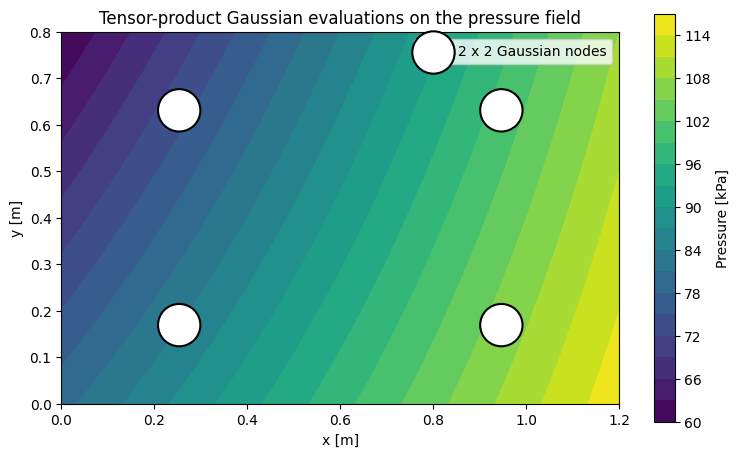

In [ ]:
fig, ax = plt.subplots(figsize=(9.0, 5.3))
contour = ax.contourf(X_plot, Y_plot, pressure_plot_kPa, levels=18, cmap="viridis")
fig.colorbar(contour, ax=ax, label="Pressure [kPa]")
marker_sizes = 130 + 800 * area_weights.ravel() / area_weights.max()
ax.scatter(
    X_gauss.ravel(),
    Y_gauss.ravel(),
    s=marker_sizes,
    facecolor="white",
    edgecolor="black",
    linewidth=1.5,
    label="2 x 2 Gaussian nodes",
)
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title("Tensor-product Gaussian evaluations on the pressure field")
ax.set_aspect("equal")
ax.legend()
plt.show()


The pressure model is degree 1 in each coordinate separately, including the
product term $xy$. A two-point rule in each direction is therefore more than
sufficient for exact integration to floating-point precision.

Tensor-product exactness is described **in each coordinate**. An $n_x\times n_y$
rule is exact when the polynomial degree is at most $2n_x-1$ in $x$ and at most
$2n_y-1$ in $y$.


## 📂 6.5.6 Convergence for a localised pressure feature

A smooth but localised feature is less favourable than the bilinear verification
model. We add a Gaussian-shaped pressure concentration near $(0.82L,0.62H)$ and
compare tensor-product orders.

The feature is synthetic. It is included to show that higher-dimensional node
placement must still resolve the important spatial behaviour.


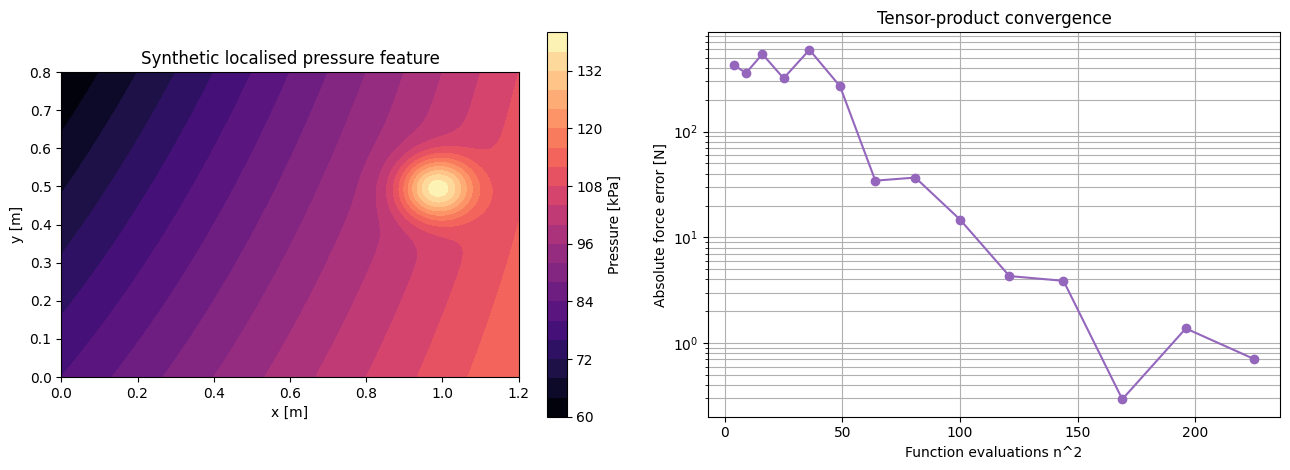

In [ ]:
def localised_pressure_Pa(x_m, y_m):
    base = plate_pressure_Pa(x_m, y_m)
    x_scale = 0.08 * plate_length_m
    y_scale = 0.10 * plate_height_m
    concentration = 35_000.0 * np.exp(
        -((x_m - 0.82 * plate_length_m) / x_scale) ** 2
        -((y_m - 0.62 * plate_height_m) / y_scale) ** 2
    )
    return base + concentration


localised_reference_N, _ = dblquad(
    lambda y_m, x_m: localised_pressure_Pa(x_m, y_m),
    0.0,
    plate_length_m,
    0.0,
    plate_height_m,
    epsabs=1e-7,
)

tensor_orders = np.arange(2, 16)
tensor_errors = []
for order in tensor_orders:
    estimate, _, _, _ = tensor_gauss_2d(
        localised_pressure_Pa,
        (0.0, plate_length_m),
        (0.0, plate_height_m),
        order,
        order,
    )
    tensor_errors.append(abs(localised_reference_N - estimate))

local_pressure_plot = localised_pressure_Pa(X_plot, Y_plot) / 1000.0

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
contour = axes[0].contourf(X_plot, Y_plot, local_pressure_plot, levels=20, cmap="magma")
fig.colorbar(contour, ax=axes[0], label="Pressure [kPa]")
axes[0].set_xlabel("x [m]")
axes[0].set_ylabel("y [m]")
axes[0].set_title("Synthetic localised pressure feature")
axes[0].set_aspect("equal")

axes[1].semilogy(tensor_orders**2, tensor_errors, "o-", color="tab:purple")
axes[1].set_xlabel("Function evaluations n^2")
axes[1].set_ylabel("Absolute force error [N]")
axes[1].set_title("Tensor-product convergence")
axes[1].grid(True, which="both")

plt.tight_layout()
plt.show()


Accuracy does not have to improve monotonically at low orders. A particular node
set may miss or overrepresent the localised feature. Convergence should be
inspected across several justified orders rather than inferred from one pair.


## 📂 6.5.7 Coordinate-dependent bounds: a triangular plate

Not every domain is rectangular. Consider the triangle with vertices
$(0,0)$, $(L,0)$ and $(0,H)$. For each fixed $x$,

$$
0\leq y\leq H\left(1-\frac{x}{L}\right).
$$

The region integral is

$$
I=\int_0^L\left[
\int_0^{H(1-x/L)}q(x,y)\,\mathrm{d}y
\right]\mathrm{d}x.
$$

The upper $y$ bound depends on the current outer coordinate $x$. Integrating 1
over the region must reproduce the geometric area $LH/2$.


,Quantity,Value,Units
0,Integrated area,0.48,m^2
1,Geometric area,0.48,m^2
2,Pressure resultant,41440.00,N


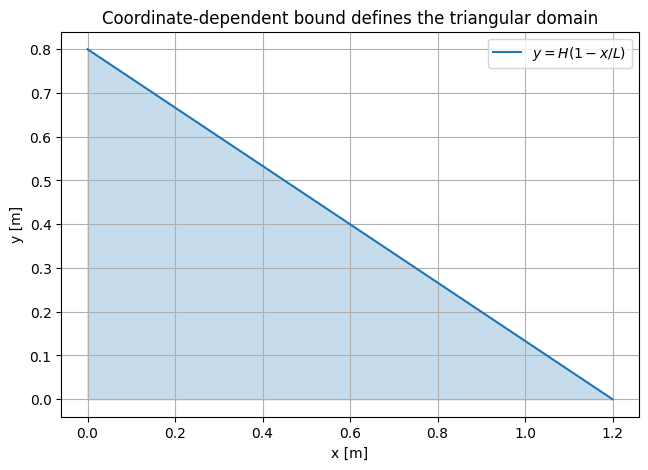

In [ ]:
triangle_upper_y = lambda x_m: plate_height_m * (1.0 - x_m / plate_length_m)

triangle_area_m2, triangle_area_error = dblquad(
    lambda y_m, x_m: 1.0,
    0.0,
    plate_length_m,
    0.0,
    triangle_upper_y,
)
triangle_force_N, _ = dblquad(
    pressure_yx,
    0.0,
    plate_length_m,
    0.0,
    triangle_upper_y,
)

triangle_results = pd.DataFrame(
    {
        "Quantity": ["Integrated area", "Geometric area", "Pressure resultant"],
        "Value": [triangle_area_m2, 0.5 * plate_length_m * plate_height_m, triangle_force_N],
        "Units": ["m^2", "m^2", "N"],
    }
)
display(triangle_results)

x_boundary = np.linspace(0.0, plate_length_m, 301)
fig, ax = plt.subplots(figsize=(8.5, 5.0))
ax.fill_between(x_boundary, 0.0, triangle_upper_y(x_boundary), alpha=0.25, color="tab:blue")
ax.plot(x_boundary, triangle_upper_y(x_boundary), color="tab:blue", label=r"$y=H(1-x/L)$")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title("Coordinate-dependent bound defines the triangular domain")
ax.set_aspect("equal")
ax.grid(True)
ax.legend()
plt.show()


Integrating over the surrounding rectangle and then masking points is not the
same numerical formulation as supplying the triangular bounds. Whichever method
is used, the domain definition must be documented and validated with a simple
area or volume calculation.


## 📂 6.5.8 Existing values on a sampled rectangular grid

Experimental and simulation data may already be stored on coordinate vectors
`x_samples`, `y_samples` and a value array `pressure_grid`.

With `np.meshgrid(x_samples, y_samples, indexing="xy")`, the resulting arrays
have shape

$$
(N_y,N_x),
$$

where rows change with $y$ and columns change with $x$. Therefore:

1. integrate along array axis 1 using `x_samples`; then
2. integrate the strip results along axis 0 using `y_samples`.

Array shape alone does not communicate physical meaning. Coordinate vectors,
indexing convention and axes must be recorded together.


In [ ]:
x_samples = np.linspace(0.0, plate_length_m, 13)
y_samples = np.linspace(0.0, plate_height_m, 9)
X_samples, Y_samples = np.meshgrid(x_samples, y_samples, indexing="xy")
pressure_grid_Pa = plate_pressure_Pa(X_samples, Y_samples)

# Axis 1 corresponds to x; the result contains one integral for each y row.
strip_forces_N_m = trapezoid(pressure_grid_Pa, x=x_samples, axis=1)
sampled_force_N = trapezoid(strip_forces_N_m, x=y_samples, axis=0)

sampled_grid_summary = pd.DataFrame(
    {
        "Method": ["Sampled-grid trapezoidal", "Callable dblquad"],
        "Resultant force [N]": [sampled_force_N, resultant_force_N],
        "Difference from dblquad [N]": [sampled_force_N - resultant_force_N, 0.0],
    }
)
display(sampled_grid_summary)
print("pressure_grid shape (Ny, Nx):", pressure_grid_Pa.shape)
print("strip result shape (Ny,):", strip_forces_N_m.shape)


,Method,Resultant force [N],Difference from dblquad [N]
0,Sampled-grid trapezoidal,87360.0,1.455191523e-11
1,Callable dblquad,87360.0,0.000000000e+00


pressure_grid shape (Ny, Nx): (9, 13)
strip result shape (Ny,): (9,)


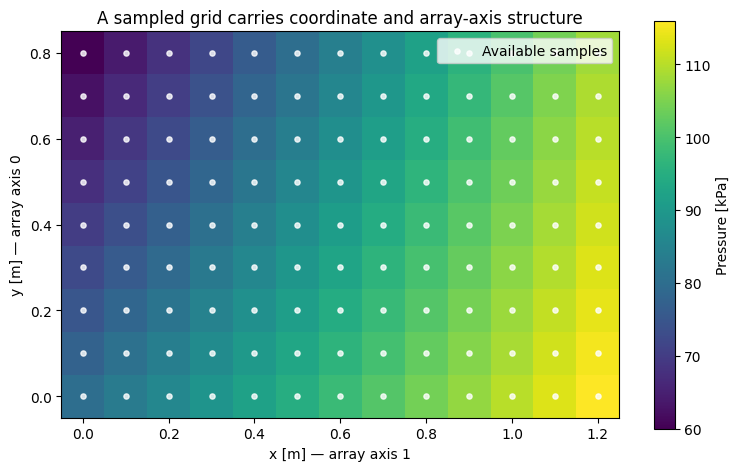

In [ ]:
fig, ax = plt.subplots(figsize=(9.0, 5.3))
image = ax.pcolormesh(X_samples, Y_samples, pressure_grid_Pa / 1000.0, shading="auto", cmap="viridis")
fig.colorbar(image, ax=ax, label="Pressure [kPa]")
ax.scatter(X_samples, Y_samples, s=14, color="white", alpha=0.8, label="Available samples")
ax.set_xlabel("x [m] — array axis 1")
ax.set_ylabel("y [m] — array axis 0")
ax.set_title("A sampled grid carries coordinate and array-axis structure")
ax.set_aspect("equal")
ax.legend()
plt.show()


The bilinear pressure model makes the trapezoidal result exact on this rectangular
grid. That is a property of this verification model, not a guarantee for measured
fields. Missing cells, irregular two-dimensional sampling and scattered point
clouds require additional data handling or a different integration strategy.


## 📂 6.5.9 Extending to three dimensions: component mass

A rectangular component has dimensions $L_b$, $W_b$ and $H_b$. Its density varies
as

$$
\rho(x,y,z)=\rho_0\left(
1+a_\rho\frac{x}{L_b}
+b_\rho\frac{y}{W_b}
+c_\rho\frac{z}{H_b}
\right).
$$

The component mass is

$$
m=\int_0^{H_b}\int_0^{W_b}\int_0^{L_b}
\rho(x,y,z)\,\mathrm{d}x\,\mathrm{d}y\,\mathrm{d}z.
$$

Here $m$ is mass in kilograms, $\rho$ is density in kg/m$^3$, and
$\mathrm{d}x\,\mathrm{d}y\,\mathrm{d}z$ has units m$^3$.

`nquad` lists bounds from the innermost coordinate to the outermost. The callable
arguments must follow the same order.


In [ ]:
block_length_m = 0.40
block_width_m = 0.25
block_height_m = 0.12
reference_density_kg_m3 = 2700.0
density_x_coefficient = 0.08
density_y_coefficient = -0.04
density_z_coefficient = 0.12


def block_density_kg_m3(x_m, y_m, z_m):
    return reference_density_kg_m3 * (
        1.0
        + density_x_coefficient * x_m / block_length_m
        + density_y_coefficient * y_m / block_width_m
        + density_z_coefficient * z_m / block_height_m
    )


block_mass_kg, mass_error_estimate = nquad(
    block_density_kg_m3,
    [
        [0.0, block_length_m],  # x: innermost
        [0.0, block_width_m],   # y
        [0.0, block_height_m],  # z: outermost
    ],
)

analytical_mass_kg = (
    reference_density_kg_m3
    * block_length_m
    * block_width_m
    * block_height_m
    * (
        1.0
        + 0.5 * density_x_coefficient
        + 0.5 * density_y_coefficient
        + 0.5 * density_z_coefficient
    )
)

mass_summary = pd.DataFrame(
    {
        "Calculation": ["scipy.integrate.nquad", "Analytical verification"],
        "Mass [kg]": [block_mass_kg, analytical_mass_kg],
        "Absolute difference [kg]": [abs(block_mass_kg - analytical_mass_kg), 0.0],
    }
)
display(mass_summary)
print(f"nquad error estimate: {mass_error_estimate:.3e} kg")


,Calculation,Mass [kg],Absolute difference [kg]
0,scipy.integrate.nquad,34.992,7.105427358e-15
1,Analytical verification,34.992,0.000000000e+00


nquad error estimate: 1.390e-11 kg


## 📂 6.5.10 Tensor-product cost grows rapidly

If a tensor-product rule uses $n$ nodes in each of $d$ dimensions, the total
evaluations are

$$N_{\mathrm{eval}}=n^d,$$

where:

* $n$ is the one-dimensional quadrature order;
* $d$ is the number of dimensions; and
* $N_{\mathrm{eval}}$ is the total number of combinations of nodes.

This rapid growth is often called the **curse of dimensionality**. A ten-point
rule uses 10 evaluations in one dimension, 100 in two dimensions, 1000 in three,
and one million in six dimensions.


,n=2,n=3,n=5,n=10
d=1,2,3,5,10
d=2,4,9,25,100
d=3,8,27,125,1000
d=4,16,81,625,10000
d=5,32,243,3125,100000
d=6,64,729,15625,1000000


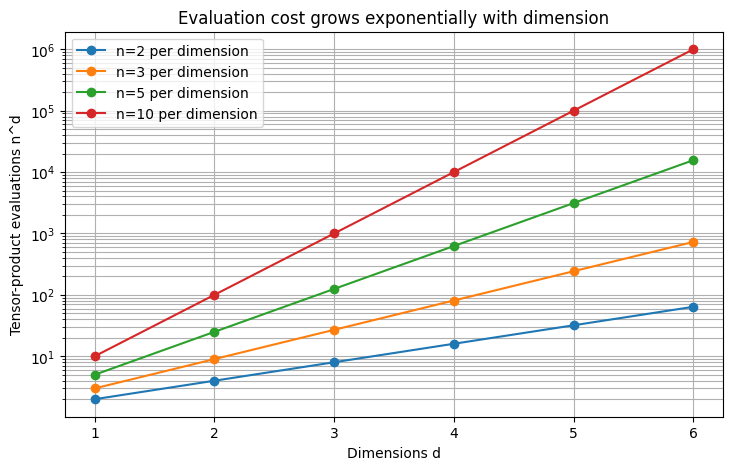

In [ ]:
dimensions = np.arange(1, 7)
orders = [2, 3, 5, 10]

evaluation_table = pd.DataFrame(
    {f"n={order}": order**dimensions for order in orders},
    index=[f"d={dimension}" for dimension in dimensions],
)
display(evaluation_table)

fig, ax = plt.subplots()
for order in orders:
    ax.semilogy(dimensions, order**dimensions, "o-", label=f"n={order} per dimension")
ax.set_xlabel("Dimensions d")
ax.set_ylabel("Tensor-product evaluations n^d")
ax.set_title("Evaluation cost grows exponentially with dimension")
ax.set_xticks(dimensions)
ax.grid(True, which="both")
ax.legend()
plt.show()


Tensor products remain highly useful in low-dimensional, structured problems.
Higher-dimensional problems may require adaptive cubature, sparse grids, Monte
Carlo methods, quasi-Monte Carlo methods or problem-specific transformations.
Choosing among them requires information about smoothness, domain geometry,
dimensionality and function-evaluation cost.


## 📂 6.5.11 Validation checks for multidimensional integrals

Useful independent checks include:

* integrate 1 to recover known area or volume;
* use uniform pressure to recover geometric-centre symmetry;
* compare units before and after each integration direction;
* reverse integration order when the domain and method allow it;
* compare callable and sampled-grid implementations on a manufactured field;
* refine node order or grid spacing and inspect convergence;
* compare against conservation laws or finite-element resultants; and
* plot both the field and the domain rather than validating only a scalar result.

Two methods can agree while sharing the same incorrect domain, units or data.
Validation should include physical and geometric evidence.


## 📂 6.5.12 Optional interactive centre of pressure

Adjust the $x$ and $y$ pressure-gradient coefficients. The display recalculates
the resultant and centre of pressure analytically for this bilinear teaching
model, then plots the shifted line of action.

The controls change $\alpha$ and $\beta$. The interaction coefficient $\gamma$
remains fixed at 0.15.


In [ ]:
def plot_pressure_gradient(alpha=0.45, beta=-0.25):
    gamma = gamma_pressure
    L = plate_length_m
    H = plate_height_m
    p0 = reference_pressure_Pa

    force = p0 * L * H * (1.0 + alpha / 2.0 + beta / 2.0 + gamma / 4.0)
    moment_y = p0 * L**2 * H * (0.5 + alpha / 3.0 + beta / 4.0 + gamma / 6.0)
    moment_x = p0 * L * H**2 * (0.5 + alpha / 4.0 + beta / 3.0 + gamma / 6.0)
    x_cp = moment_y / force
    y_cp = moment_x / force

    pressure = p0 * (
        1.0
        + alpha * X_plot / L
        + beta * Y_plot / H
        + gamma * X_plot * Y_plot / (L * H)
    ) / 1000.0

    fig, ax = plt.subplots(figsize=(9.0, 5.3))
    contour = ax.contourf(X_plot, Y_plot, pressure, levels=18, cmap="viridis")
    fig.colorbar(contour, ax=ax, label="Pressure [kPa]")
    ax.plot(L / 2.0, H / 2.0, "+", markersize=14, markeredgewidth=2.5, color="white", label="Geometric centre")
    ax.plot(x_cp, y_cp, "X", markersize=11, color="tab:red", label="Centre of pressure")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_title(f"Resultant={force/1000:.2f} kN, centre=({x_cp:.3f}, {y_cp:.3f}) m")
    ax.set_aspect("equal")
    ax.legend()
    plt.show()


try:
    import ipywidgets as widgets

    widgets.interact(
        plot_pressure_gradient,
        alpha=widgets.FloatSlider(value=0.45, min=-0.5, max=0.8, step=0.05, description="alpha", continuous_update=False),
        beta=widgets.FloatSlider(value=-0.25, min=-0.5, max=0.8, step=0.05, description="beta", continuous_update=False),
    )
except ImportError:
    print("ipywidgets is unavailable; showing the default pressure field.")
    plot_pressure_gradient(alpha=0.45, beta=-0.25)


interactive(children=(FloatSlider(value=0.45, continuous_update=False, description='alpha', max=0.8, min=-0.5,…

## 📂 6.5.13 Method selection

| Data and domain | Suitable starting method | Important caution |
|---|---|---|
| Smooth callable on a rectangle | tensor Gaussian or adaptive cubature | inspect localised features and cost |
| Callable with simple variable bounds | `dblquad` or `nquad` | match callable argument and bound order |
| Existing complete rectangular grid | repeated sampled-data integration | document coordinates, indexing and axes |
| Triangular or curved region | coordinate-dependent bounds or transformation | validate area before the physical integral |
| Scattered measurements | interpolation, meshing or specialised method | preprocessing adds assumptions |
| Many dimensions | adaptive, sparse or sampling-based methods | tensor cost grows as $n^d$ |
| Field with discontinuities or singularities | split domain or specialised rule | one smooth global approximation may fail |

The mathematical dimension, domain geometry and source of the data are all part
of method selection.


## 📂 6.5.14 Common interpretation failures

| Failure | Why it is unsafe | Better action |
|---|---|---|
| Swapping `dblquad` arguments | values are evaluated at the wrong coordinates | define a named `function(y, x)` wrapper |
| Using rectangular bounds for a triangular part | extra area is integrated | plot and validate the domain |
| Integrating an array along the wrong axis | coordinates no longer match values | document shape and use explicit `axis` arguments |
| Forgetting the second integration | strip result is mistaken for a total | check output shape and units |
| Treating an error estimate as physical uncertainty | only numerical quadrature is assessed | analyse data and model uncertainty separately |
| Applying Gaussian nodes to unavailable measurements | values are invented by interpolation | distinguish callable models from fixed data |
| Increasing order without tracking $n^d$ | cost can become excessive | report evaluation count and use structure |
| Reporting only one scalar | domain or field errors remain hidden | visualise geometry and distributed values |


## 📂 6.5.15 Useful packages and functions

| Package | Function or technique | Purpose | Important caution |
|---|---|---|---|
| SciPy | `integrate.dblquad` | adaptive double integration with $y$ bounds depending on $x$ | callable signature is `func(y, x)` |
| SciPy | `integrate.nquad` | general nested multidimensional integration | ranges follow innermost-to-outermost argument order |
| NumPy | `meshgrid(..., indexing="xy")` | build coordinate arrays from coordinate vectors | output shape is $(N_y,N_x)$ in 2D |
| SciPy | `integrate.trapezoid(..., axis=...)` | integrate sampled arrays one direction at a time | coordinate vector must match that axis |
| NumPy | `leggauss` and outer weight products | construct tensor Gauss–Legendre rules | evaluations grow multiplicatively |
| Matplotlib | `contourf`, `pcolormesh`, `scatter` | visualise domains, fields and nodes | a plausible field plot is not independent validation |


## 📂 6.5.16 Engineering workflow and summary

A defensible multidimensional integration workflow is:

1. define the accumulated physical quantity and its units;
2. define and plot the integration domain $\Omega$;
3. identify whether the source is a callable function or fixed sampled data;
4. choose coordinate order, bounds and array indexing explicitly;
5. validate the domain by integrating 1 to recover area or volume;
6. choose a method that matches the geometry and data source;
7. refine quadrature order, panels or grid resolution and inspect convergence;
8. verify symmetry, units and a manufactured analytical case;
9. track evaluation cost as dimensionality increases; and
10. report the result together with geometry, numerical evidence and limitations.

**Key result:** multidimensional integration accumulates a distributed quantity
over an area, volume or higher-dimensional domain. Reliable results require the
integrand, bounds, coordinate order, units and data structure to describe the same
physical geometry.


## 📚 References

* SciPy developers, *`scipy.integrate.dblquad`*, stable documentation.
* SciPy developers, *`scipy.integrate.nquad`*, stable documentation.
* SciPy developers, *General multiple integration*, user guide.
* NumPy developers, *`numpy.meshgrid`*, stable documentation.

## 🤖 AI Acknowledgment

Generative AI was used to help structure explanations, develop deterministic
teaching examples and review code. The teaching team remains responsible for the
mathematics, engineering interpretation, source selection and final notebook.
